In [5]:
import pandas as pd

def process_era5_csv(file_path, var_name):
    
    df = pd.read_csv(file_path)
    
    # Convert time
    df['valid_time'] = pd.to_datetime(df['valid_time'])
    
    # Keep only required columns
    df = df[['valid_time', var_name]]
    
    # Rename time column
    df = df.rename(columns={'valid_time': 'time'})
    
    # Set index
    df = df.set_index('time')
    
    return df

In [7]:
import os
print(os.listdir())

['AMF_US-ARM_BASE_HH_15-5.csv', 'AMF_US-ARM_BIF_20240229.xlsx', 'Hourly_MultiFeature_Model.ipynb', 'Prediction_USing_ML_Model.ipynb', 'reanalysis-era5-land-timeseries-sfc-2m-temperaturectwi9b5c.csv', 'reanalysis-era5-land-timeseries-sfc-2m-temperaturenvjcpbxi.csv', 'reanalysis-era5-land-timeseries-sfc-pressure-precipitationp58iih4w.csv', 'reanalysis-era5-land-timeseries-sfc-radiation-heatyz_opg_o.csv', 'reanalysis-era5-land-timeseries-sfc-soil-temperature_szthbx0.csv', 'reanalysis-era5-land-timeseries-sfc-soil-watery5wmeq3m.csv', 'SMAP_data_validation.ipynb', 'SMAP_L3_SM_P_E_20150801_R19240_001.h5', 'SMAP_L3_SM_P_E_20150802_R19240_001.h5', 'SMAP_L3_SM_P_E_20150803_R19240_001.h5', 'SMAP_L3_SM_P_E_20150804_R19240_001.h5', 'SMAP_L3_SM_P_E_20150805_R19240_001.h5', 'SMAP_L3_SM_P_E_20150806_R19240_001.h5', 'SMAP_L3_SM_P_E_20150807_R19240_001.h5', 'SMAP_L3_SM_P_E_20150808_R19240_001.h5', 'SMAP_L3_SM_P_E_20150809_R19240_001.h5', 'SMAP_L3_SM_P_E_20150810_R19240_001.h5', 'SMAP_L3_SM_P_E_20150811

In [8]:
df_swvl1 = process_era5_csv(
    "reanalysis-era5-land-timeseries-sfc-soil-watery5wmeq3m.csv",
    "swvl1"
)

print(df_swvl1.head())
print(df_swvl1.columns)

                        swvl1
time                         
2003-01-01 00:00:00  0.328949
2003-01-01 01:00:00  0.328629
2003-01-01 02:00:00  0.328323
2003-01-01 03:00:00  0.328064
2003-01-01 04:00:00  0.327805
Index(['swvl1'], dtype='str')


In [10]:
pd.read_csv("reanalysis-era5-land-timeseries-sfc-2m-temperaturectwi9b5c.csv").columns

Index(['valid_time', 'd2m', 'latitude', 'longitude'], dtype='str')

In [11]:
import pandas as pd

# List of ERA5 files (from your folder)
files = [
    "reanalysis-era5-land-timeseries-sfc-soil-watery5wmeq3m.csv",
    "reanalysis-era5-land-timeseries-sfc-2m-temperaturectwi9b5c.csv",
    "reanalysis-era5-land-timeseries-sfc-pressure-precipitationp58iih4w.csv",
    "reanalysis-era5-land-timeseries-sfc-radiation-heatyz_opg_o.csv",
    "reanalysis-era5-land-timeseries-sfc-soil-temperature_szthbx0.csv"
]

dfs = []

for file in files:
    df = pd.read_csv(file)
    
    # Convert time
    df['valid_time'] = pd.to_datetime(df['valid_time'])
    
    # Identify variable column automatically
    cols = df.columns.tolist()
    cols.remove('valid_time')
    
    if 'latitude' in cols:
        cols.remove('latitude')
    if 'longitude' in cols:
        cols.remove('longitude')
    
    var_name = cols[0]   # remaining column is variable
    
    # Keep only time + variable
    df = df[['valid_time', var_name]]
    
    # Rename columns
    df = df.rename(columns={
        'valid_time': 'time',
        var_name: var_name
    })
    
    # Set index
    df = df.set_index('time')
    
    dfs.append(df)

# Merge all variables
df_era5_final = pd.concat(dfs, axis=1)

# Drop missing values
df_era5_final = df_era5_final.dropna()

print(df_era5_final.head())
print(df_era5_final.columns)
print(df_era5_final.shape)

                        swvl1        d2m   tp     ssrd       stl1
time                                                             
2003-01-01 00:00:00  0.328949  268.92886  0.0  19164.0  280.14470
2003-01-01 01:00:00  0.328629  268.86000  0.0      0.0  278.94202
2003-01-01 02:00:00  0.328323  269.64000  0.0      0.0  277.90270
2003-01-01 03:00:00  0.328064  268.72717  0.0      0.0  276.85740
2003-01-01 04:00:00  0.327805  268.76044  0.0      0.0  276.13525
Index(['swvl1', 'd2m', 'tp', 'ssrd', 'stl1'], dtype='str')
(201624, 5)


In [12]:
df_era5_final = df_era5_final.rename(columns={
    'swvl1': 'soil_moisture_era5',
    'd2m': 'dewpoint_temp',
    'tp': 'precipitation',
    'ssrd': 'radiation',
    'stl1': 'soil_temp'
})

print(df_era5_final.head())
print(df_era5_final.columns)

                     soil_moisture_era5  dewpoint_temp  precipitation  \
time                                                                    
2003-01-01 00:00:00            0.328949      268.92886            0.0   
2003-01-01 01:00:00            0.328629      268.86000            0.0   
2003-01-01 02:00:00            0.328323      269.64000            0.0   
2003-01-01 03:00:00            0.328064      268.72717            0.0   
2003-01-01 04:00:00            0.327805      268.76044            0.0   

                     radiation  soil_temp  
time                                       
2003-01-01 00:00:00    19164.0  280.14470  
2003-01-01 01:00:00        0.0  278.94202  
2003-01-01 02:00:00        0.0  277.90270  
2003-01-01 03:00:00        0.0  276.85740  
2003-01-01 04:00:00        0.0  276.13525  
Index(['soil_moisture_era5', 'dewpoint_temp', 'precipitation', 'radiation',
       'soil_temp'],
      dtype='str')


In [15]:
import pandas as pd

# Load AmeriFlux file by skipping metadata rows
df_amf = pd.read_csv(
    "AMF_US-ARM_BASE_HH_15-5.csv",
    skiprows=2   # skip first 2 metadata lines
)

# Convert timestamp
df_amf['time'] = pd.to_datetime(df_amf['TIMESTAMP_START'], format='%Y%m%d%H%M')

# Set time index
df_amf = df_amf.set_index('time')

# Find soil moisture columns
swc_cols = [col for col in df_amf.columns if 'SWC' in col]
print("Available soil moisture columns:", swc_cols)

# Select first soil moisture column
df_amf = df_amf[[swc_cols[0]]]

# Rename column
df_amf = df_amf.rename(columns={swc_cols[0]: 'soil_moisture_amf'})

# Replace missing values (-9999)
df_amf = df_amf.replace(-9999, pd.NA)

# Drop missing
df_amf = df_amf.dropna()

# Convert half-hourly to hourly
df_amf_hourly = df_amf.resample('h').mean()

# Final check
print(df_amf_hourly.head())
print(df_amf_hourly.shape)

C:\Users\prath\AppData\Local\Temp\ipykernel_25676\1864044731.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_amf['time'] = pd.to_datetime(df_amf['TIMESTAMP_START'], format='%Y%m%d%H%M')


Available soil moisture columns: ['SWC_1_2_1', 'SWC_1_2_2', 'SWC_1_1_1', 'SWC_1_1_2', 'SWC_1_2_3', 'SWC_1_2_4', 'SWC_1_1_3', 'SWC_1_1_4', 'SWC_2_1_1', 'SWC_2_2_1', 'SWC_2_3_1', 'SWC_2_4_1', 'SWC_2_5_1', 'SWC_2_6_1', 'SWC_3_1_1', 'SWC_3_1_2', 'SWC_3_2_1', 'SWC_3_2_2', 'SWC_3_3_1', 'SWC_3_3_2']
                    soil_moisture_amf
time                                 
2003-01-01 23:00:00             43.84
2003-01-02 00:00:00               NaN
2003-01-02 01:00:00               NaN
2003-01-02 02:00:00               NaN
2003-01-02 03:00:00               NaN
(106550, 1)


In [20]:
import pandas as pd

df_amf = pd.read_csv("AMF_US-ARM_BASE_HH_15-5.csv", skiprows=2)

df_amf['time'] = pd.to_datetime(df_amf['TIMESTAMP_START'], format='%Y%m%d%H%M')
df_amf = df_amf.set_index('time')

# Only 0–10 cm sensors
swc_cols = ['SWC_1_1_1', 'SWC_1_1_2', 'SWC_1_1_3', 'SWC_1_1_4']

df_amf = df_amf[swc_cols]

df_amf = df_amf.replace(-9999, pd.NA)
df_amf = df_amf.dropna(how='all')

# Average sensors
df_amf['soil_moisture_amf'] = df_amf.mean(axis=1)

df_amf = df_amf[['soil_moisture_amf']]

df_amf_hourly = df_amf.resample('h').mean()
df_amf_hourly = df_amf_hourly.dropna()

print(df_amf_hourly.head())
print(df_amf_hourly.shape)

C:\Users\prath\AppData\Local\Temp\ipykernel_25676\303973182.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_amf['time'] = pd.to_datetime(df_amf['TIMESTAMP_START'], format='%Y%m%d%H%M')


                    soil_moisture_amf
time                                 
2003-01-01 18:00:00             27.31
2003-01-01 19:00:00          27.25875
2003-01-01 20:00:00           27.2375
2003-01-01 21:00:00              27.2
2003-01-01 22:00:00           27.1725
(78619, 1)


In [21]:
# Convert AmeriFlux to same unit as ERA5
df_amf_hourly['soil_moisture_amf'] = df_amf_hourly['soil_moisture_amf'] / 100

# Merge ERA5 + AmeriFlux on time
df_final = df_era5_final.join(df_amf_hourly, how='inner')

# Drop any remaining missing values
df_final = df_final.dropna()

# Final check
print(df_final.head())
print(df_final.shape)
print(df_final.columns)

                     soil_moisture_era5  dewpoint_temp  precipitation  \
time                                                                    
2003-01-01 18:00:00            0.323135      268.05090   4.294766e-07   
2003-01-01 19:00:00            0.322495      268.31125   1.803604e-05   
2003-01-01 20:00:00            0.321869      268.66544   2.029538e-05   
2003-01-01 21:00:00            0.321381      268.72308   2.765043e-05   
2003-01-01 22:00:00            0.321121      268.41210   3.732460e-05   

                     radiation  soil_temp soil_moisture_amf  
time                                                         
2003-01-01 18:00:00   991920.0  278.40216            0.2731  
2003-01-01 19:00:00  1382372.0  279.40344          0.272587  
2003-01-01 20:00:00  1390416.0  279.93372          0.272375  
2003-01-01 21:00:00  1261860.0  280.02417             0.272  
2003-01-01 22:00:00   770464.0  279.55582          0.271725  
(78619, 6)
Index(['soil_moisture_era5', 'dewpoint_temp

In [22]:
print(df_final.describe())
print(df_final.corr())

       soil_moisture_era5  dewpoint_temp  precipitation     radiation  \
count        78619.000000   78619.000000   7.861900e+04  7.861900e+04   
mean             0.266427     278.788525   8.472202e-05  6.967065e+05   
std              0.073367      10.452402   4.842865e-04  9.811529e+05   
min              0.136597     240.322950  -3.270429e-08 -4.000000e+00   
25%              0.206604     270.812635   0.000000e+00  0.000000e+00   
50%              0.271133     279.072270   0.000000e+00  2.296150e+04   
75%              0.322289     288.217545   4.351138e-07  1.294996e+06   
max              0.438995     298.834350   1.539744e-02  3.650924e+06   

          soil_temp  
count  78619.000000  
mean     288.717609  
std       11.099149  
min      266.874270  
25%      279.411620  
50%      287.651180  
75%      297.457025  
max      323.774050  
                    soil_moisture_era5  dewpoint_temp  precipitation  \
soil_moisture_era5            1.000000      -0.158384       0.224128   


In [24]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\prath\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


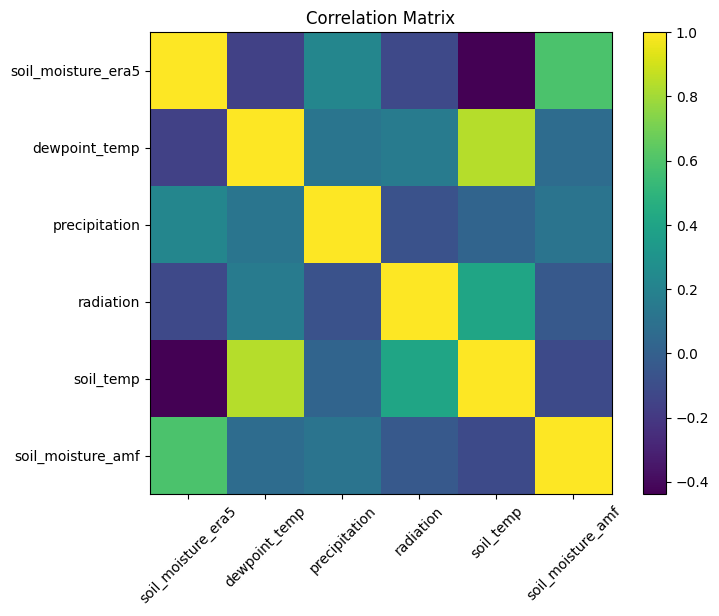

In [25]:
import matplotlib.pyplot as plt
import numpy as np

corr = df_final.corr()

plt.figure(figsize=(8,6))
plt.imshow(corr, interpolation='none')
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Matrix")
plt.show()

In [26]:
# Make a copy (safe practice)
df_clean = df_final.copy()

# Remove negative precipitation
df_clean = df_clean[df_clean['precipitation'] >= 0]

# Remove negative radiation
df_clean = df_clean[df_clean['radiation'] >= 0]

# Soil moisture must be between 0 and 1
df_clean = df_clean[(df_clean['soil_moisture_era5'] >= 0) & (df_clean['soil_moisture_era5'] <= 1)]
df_clean = df_clean[(df_clean['soil_moisture_amf'] >= 0) & (df_clean['soil_moisture_amf'] <= 1)]

# Temperature filtering (Kelvin, remove unrealistic values)
df_clean = df_clean[df_clean['dewpoint_temp'] > 200]
df_clean = df_clean[df_clean['soil_temp'] > 200]

# Final check
print("Original shape:", df_final.shape)
print("Cleaned shape:", df_clean.shape)

print(df_clean.describe())

Original shape: (78619, 6)
Cleaned shape: (76048, 6)
       soil_moisture_era5  dewpoint_temp  precipitation     radiation  \
count        76048.000000   76048.000000   7.604800e+04  7.604800e+04   
mean             0.266694     278.749811   8.645259e-05  6.956924e+05   
std              0.073280      10.455025   4.883409e-04  9.797293e+05   
min              0.136597     240.322950   0.000000e+00  0.000000e+00   
25%              0.207047     270.769325   0.000000e+00  0.000000e+00   
50%              0.271286     279.011185   0.000000e+00  2.512600e+04   
75%              0.322403     288.189310   4.410743e-07  1.288511e+06   
max              0.438995     298.834350   1.539744e-02  3.650924e+06   

          soil_temp  
count  76048.000000  
mean     288.638437  
std       11.096992  
min      266.874270  
25%      279.325022  
50%      287.528925  
75%      297.372695  
max      323.774050  


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor
import numpy as np

# Features and target
X = df_clean[['soil_moisture_era5', 'dewpoint_temp', 'precipitation', 'radiation', 'soil_temp']]
y = df_clean['soil_moisture_amf']

# Random split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model
model = XGBRegressor(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

# Train
model.fit(X_train, y_train)

# Predictions
y_train_pred = model.predict(X_train)
y_test_pred  = model.predict(X_test)

# Metrics
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train   = r2_score(y_train, y_train_pred)

rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2_test   = r2_score(y_test, y_test_pred)

print("----- CALIBRATION (TRAIN) -----")
print("RMSE:", rmse_train)
print("R2:", r2_train)

print("\n----- VALIDATION (TEST) -----")
print("RMSE:", rmse_test)
print("R2:", r2_test)

----- CALIBRATION (TRAIN) -----
RMSE: 0.06991911488418458
R2: 0.4803715944290161

----- VALIDATION (TEST) -----
RMSE: 0.07156081854623103
R2: 0.45633524656295776


              feature  importance
0  soil_moisture_era5    0.706189
1       dewpoint_temp    0.110121
4           soil_temp    0.100039
2       precipitation    0.050991
3           radiation    0.032661


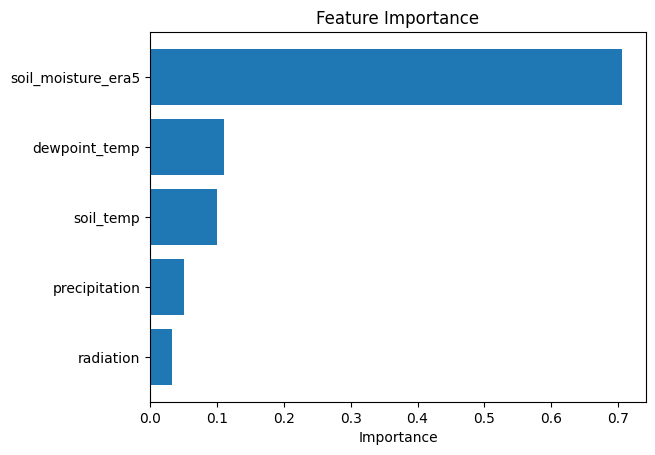

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = model.feature_importances_

feature_names = X.columns

df_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importance
}).sort_values(by='importance', ascending=False)

print(df_importance)

# Plot
plt.barh(df_importance['feature'], df_importance['importance'])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Feature Importance")
plt.show()

In [29]:
# Add ML predictions to df_clean
df_clean['ML_Model'] = model.predict(X)

In [30]:
df_aug2015 = df_clean.loc['2015-08-01':'2015-08-31']

In [31]:
df_daily = df_aug2015.resample('D').mean()

# Keep only required columns
df_daily = df_daily[[
    'soil_moisture_amf',
    'soil_moisture_era5',
    'ML_Model'
]]

# Rename for clarity
df_daily.columns = ['AmeriFlux', 'ERA5', 'ML_Model']

print(df_daily.head())

Empty DataFrame
Columns: [AmeriFlux, ERA5, ML_Model]
Index: []


In [34]:
import h5py
import numpy as np
import pandas as pd
import os

smap_data = []

# Your AmeriFlux site coordinates
target_lat = 36.5
target_lon = -97.5

files = sorted([f for f in os.listdir() if f.endswith('.h5')])

for file in files:
    file_path = file

    with h5py.File(file_path, 'r') as f:
        
        sm = f['Soil_Moisture_Retrieval_Data_AM/soil_moisture'][:]
        lat = f['Soil_Moisture_Retrieval_Data_AM/latitude'][:]
        lon = f['Soil_Moisture_Retrieval_Data_AM/longitude'][:]

        # Convert to float
        sm = sm.astype(float)

        # Replace invalid values
        sm[sm < 0] = np.nan

        # Find nearest pixel
        dist = (lat - target_lat)**2 + (lon - target_lon)**2
        idx = np.unravel_index(np.argmin(dist), dist.shape)

        # Extract exact pixel value
        sm_value = sm[idx]

        # Skip if NaN
        if np.isnan(sm_value):
            continue

        # Extract date
        date_str = file.split('_')[5]
        date = pd.to_datetime(date_str, format='%Y%m%d')

        smap_data.append([date, sm_value])

# Create dataframe
df_smap = pd.DataFrame(smap_data, columns=['Date', 'SMAP']).set_index('Date')

print(df_smap.head())
print("Total valid days:", len(df_smap))

                SMAP
Date                
2015-08-01  0.135889
2015-08-02  0.138808
2015-08-03  0.126934
2015-08-04  0.088607
2015-08-05  0.071323
Total valid days: 31


In [37]:
# Merge daily ML/ERA5/AmeriFlux with SMAP
df_compare = df_daily.join(df_smap, how='inner')

# Final check
print(df_compare.head())
print(df_compare.shape)
print(df_compare.columns)

Empty DataFrame
Columns: [AmeriFlux, ERA5, ML_Model, SMAP]
Index: []
(0, 4)
Index(['AmeriFlux', 'ERA5', 'ML_Model', 'SMAP'], dtype='str')


In [38]:
# STEP 1: Add ML predictions to hourly dataset
df_clean['ML_Model'] = model.predict(X)

# STEP 2: Filter only August 2015
df_aug2015 = df_clean.loc['2015-08-01':'2015-08-31']

# STEP 3: Convert to daily
df_daily = df_aug2015.resample('D').mean()

# STEP 4: Keep only required columns
df_daily = df_daily[[
    'soil_moisture_amf',
    'soil_moisture_era5',
    'ML_Model'
]]

# STEP 5: Rename columns (VERY IMPORTANT for consistency)
df_daily.columns = ['AmeriFlux', 'ERA5', 'ML_Model']

# STEP 6: Ensure date format matches SMAP
df_daily.index = df_daily.index.normalize()
df_smap.index = df_smap.index.normalize()

# STEP 7: Merge all datasets
df_compare = df_daily.join(df_smap, how='inner')

# STEP 8: Check
print(df_compare.head())
print("Shape:", df_compare.shape)

Empty DataFrame
Columns: [AmeriFlux, ERA5, ML_Model, SMAP]
Index: []
Shape: (0, 4)


In [39]:
print("df_daily range:", df_daily.index.min(), "→", df_daily.index.max())
print("df_smap range:", df_smap.index.min(), "→", df_smap.index.max())

df_daily range: NaT → NaT
df_smap range: 2015-08-01 00:00:00 → 2015-08-31 00:00:00


In [40]:
print(type(df_clean.index))
print(df_clean.index[:5])

<class 'pandas.DatetimeIndex'>
DatetimeIndex(['2003-01-01 18:00:00', '2003-01-01 19:00:00',
               '2003-01-01 20:00:00', '2003-01-01 21:00:00',
               '2003-01-01 22:00:00'],
              dtype='datetime64[us]', name='time', freq=None)


In [41]:
print(df_clean.loc['2015'].head())
print(df_clean.loc['2015'].shape)

                     soil_moisture_era5  dewpoint_temp  precipitation  \
time                                                                    
2015-01-01 00:00:00            0.270065      257.77620            0.0   
2015-01-01 01:00:00            0.270035      257.96045            0.0   
2015-01-01 02:00:00            0.270004      258.14185            0.0   
2015-01-01 03:00:00            0.269989      258.27625            0.0   
2015-01-01 04:00:00            0.269958      258.36743            0.0   

                     radiation  soil_temp soil_moisture_amf  ML_Model  
time                                                                   
2015-01-01 00:00:00    10560.0  272.53262           0.15905  0.168212  
2015-01-01 01:00:00        0.0  272.48700            0.1591  0.164310  
2015-01-01 02:00:00        0.0  272.43760          0.159425  0.164310  
2015-01-01 03:00:00        0.0  272.39853          0.159675  0.182526  
2015-01-01 04:00:00        0.0  272.36200              0

In [42]:
# STEP 1: Take ONLY August 2015 from df_final (not df_clean)
df_aug2015 = df_final[(df_final.index.year == 2015) & (df_final.index.month == 8)]

print("Hourly August data:", df_aug2015.shape)

# STEP 2: Add ML predictions ONLY for this subset
X_aug = df_aug2015[['soil_moisture_era5', 'dewpoint_temp', 'precipitation', 'radiation', 'soil_temp']]
df_aug2015['ML_Model'] = model.predict(X_aug)

# STEP 3: Convert to daily
df_daily = df_aug2015.resample('D').mean()

# STEP 4: Keep only required columns
df_daily = df_daily[['soil_moisture_amf', 'soil_moisture_era5', 'ML_Model']]

# STEP 5: Rename columns properly
df_daily.columns = ['AmeriFlux', 'ERA5', 'ML_Model']

print("Daily data shape:", df_daily.shape)
print(df_daily.head())

# STEP 6: Align date format
df_daily.index = pd.to_datetime(df_daily.index.date)
df_smap.index = pd.to_datetime(df_smap.index.date)

# STEP 7: Merge with SMAP
df_compare = df_daily.join(df_smap, how='inner')

print("\nFinal comparison data:")
print(df_compare.head())
print("Shape:", df_compare.shape)

Hourly August data: (0, 6)
Daily data shape: (0, 3)
Empty DataFrame
Columns: [AmeriFlux, ERA5, ML_Model]
Index: []

Final comparison data:
Empty DataFrame
Columns: [AmeriFlux, ERA5, ML_Model, SMAP]
Index: []
Shape: (0, 4)


In [43]:
print("Min date:", df_final.index.min())
print("Max date:", df_final.index.max())

Min date: 2003-01-01 18:00:00
Max date: 2015-02-27 12:00:00


In [44]:
# Extract August directly from ORIGINAL datasets

df_amf_aug = df_amf_hourly[(df_amf_hourly.index.year == 2015) & (df_amf_hourly.index.month == 8)]

df_era5_aug = df_era5_final[(df_era5_final.index.year == 2015) & (df_era5_final.index.month == 8)]

print(df_amf_aug.shape)
print(df_era5_aug.shape)

(0, 1)
(744, 5)


In [45]:
df_aug = df_era5_aug.join(df_amf_aug, how='inner')

print(df_aug.shape)

(0, 6)


In [46]:
print(df_amf_aug.shape)
print(df_era5_aug.shape)
print(df_aug.shape)

(0, 1)
(744, 5)
(0, 6)


In [47]:
df_amf = pd.read_csv("AMF_US-ARM_BASE_HH_15-5.csv", skiprows=2)

df_amf['time'] = pd.to_datetime(df_amf['TIMESTAMP_START'], format='%Y%m%d%H%M')
df_amf = df_amf.set_index('time')

C:\Users\prath\AppData\Local\Temp\ipykernel_25676\1471973348.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_amf['time'] = pd.to_datetime(df_amf['TIMESTAMP_START'], format='%Y%m%d%H%M')


In [48]:
df_amf_aug = df_amf[(df_amf.index.year == 2015) & (df_amf.index.month == 8)]

print("Raw AMF August:", df_amf_aug.shape)

Raw AMF August: (1488, 140)


In [50]:
# Merge ERA5 + AmeriFlux (DO NOT use inner join)
df_full = df_era5_final.join(df_amf_hourly, how='left')

print(df_full.shape)
print(df_full.head())

(201624, 6)
                     soil_moisture_era5  dewpoint_temp  precipitation  \
time                                                                    
2003-01-01 00:00:00            0.328949      268.92886            0.0   
2003-01-01 01:00:00            0.328629      268.86000            0.0   
2003-01-01 02:00:00            0.328323      269.64000            0.0   
2003-01-01 03:00:00            0.328064      268.72717            0.0   
2003-01-01 04:00:00            0.327805      268.76044            0.0   

                     radiation  soil_temp soil_moisture_amf  
time                                                         
2003-01-01 00:00:00    19164.0  280.14470               NaN  
2003-01-01 01:00:00        0.0  278.94202               NaN  
2003-01-01 02:00:00        0.0  277.90270               NaN  
2003-01-01 03:00:00        0.0  276.85740               NaN  
2003-01-01 04:00:00        0.0  276.13525               NaN  


In [51]:
df_model = df_full.dropna(subset=['soil_moisture_amf'])

print(df_model.shape)

(78619, 6)


In [55]:
import os
print(os.listdir())

['AMF_US-ARM_BASE_HH_15-5.csv', 'AMF_US-ARM_BIF_20240229.xlsx', 'Hourly_MultiFeature_Model.ipynb', 'Prediction_USing_ML_Model.ipynb', 'reanalysis-era5-land-timeseries-sfc-2m-temperaturectwi9b5c.csv', 'reanalysis-era5-land-timeseries-sfc-2m-temperaturenvjcpbxi.csv', 'reanalysis-era5-land-timeseries-sfc-pressure-precipitationp58iih4w.csv', 'reanalysis-era5-land-timeseries-sfc-radiation-heatyz_opg_o.csv', 'reanalysis-era5-land-timeseries-sfc-soil-temperature_szthbx0.csv', 'reanalysis-era5-land-timeseries-sfc-soil-watery5wmeq3m.csv', 'SMAP_data_validation.ipynb', 'SMAP_L3_SM_P_E_20150801_R19240_001.h5', 'SMAP_L3_SM_P_E_20150802_R19240_001.h5', 'SMAP_L3_SM_P_E_20150803_R19240_001.h5', 'SMAP_L3_SM_P_E_20150804_R19240_001.h5', 'SMAP_L3_SM_P_E_20150805_R19240_001.h5', 'SMAP_L3_SM_P_E_20150806_R19240_001.h5', 'SMAP_L3_SM_P_E_20150807_R19240_001.h5', 'SMAP_L3_SM_P_E_20150808_R19240_001.h5', 'SMAP_L3_SM_P_E_20150809_R19240_001.h5', 'SMAP_L3_SM_P_E_20150810_R19240_001.h5', 'SMAP_L3_SM_P_E_20150811

In [57]:
import pandas as pd

# Load AmeriFlux file (skip metadata rows)
df_amf = pd.read_csv("AMF_US-ARM_BASE_HH_15-5.csv", skiprows=2)

# Check structure
print("Shape:", df_amf.shape)

print("\nColumns:\n")
print(df_amf.columns)

print("\nFirst 5 rows:\n")
print(df_amf.head())

Shape: (403284, 140)

Columns:

Index(['TIMESTAMP_START', 'TIMESTAMP_END', 'TAU_1_1_1', 'H_1_1_1', 'LE_1_1_1',
       'FC_1_1_1', 'WS_1_1_1', 'WS_MAX_1_1_1', 'WD_1_1_1', 'USTAR_1_1_1',
       ...
       'TS_3_2_1', 'SWC_3_2_2', 'TS_3_2_2', 'SWC_3_3_1', 'TS_3_3_1',
       'SWC_3_3_2', 'TS_3_3_2', 'SW_DIR_1_1_1', 'SW_DIF_1_1_1',
       'T_CANOPY_1_1_1'],
      dtype='str', length=140)

First 5 rows:

   TIMESTAMP_START  TIMESTAMP_END  TAU_1_1_1  H_1_1_1  LE_1_1_1  FC_1_1_1  \
0     200301010000   200301010030    -9999.0  -9999.0   -9999.0   -9999.0   
1     200301010030   200301010100    -9999.0  -9999.0   -9999.0   -9999.0   
2     200301010100   200301010130    -9999.0  -9999.0   -9999.0   -9999.0   
3     200301010130   200301010200    -9999.0  -9999.0   -9999.0   -9999.0   
4     200301010200   200301010230    -9999.0  -9999.0   -9999.0   -9999.0   

   WS_1_1_1  WS_MAX_1_1_1  WD_1_1_1  USTAR_1_1_1  ...  TS_3_2_1  SWC_3_2_2  \
0   -9999.0       -9999.0   -9999.0      -9999.0  ...   -

In [58]:
# Select timestamp + all SWC columns
swc_cols = [col for col in df_amf.columns if "SWC" in col]

df_swc = df_amf[["TIMESTAMP_START"] + swc_cols]

# Replace missing values (-9999) with NaN
df_swc = df_swc.replace(-9999, pd.NA)

# Show results
print("Selected SWC columns:\n", swc_cols)

print("\nFirst 5 rows:\n")
print(df_swc.head())

print("\nLast 5 rows:\n")
print(df_swc.tail())

Selected SWC columns:
 ['SWC_1_2_1', 'SWC_1_2_2', 'SWC_1_1_1', 'SWC_1_1_2', 'SWC_1_2_3', 'SWC_1_2_4', 'SWC_1_1_3', 'SWC_1_1_4', 'SWC_2_1_1', 'SWC_2_2_1', 'SWC_2_3_1', 'SWC_2_4_1', 'SWC_2_5_1', 'SWC_2_6_1', 'SWC_3_1_1', 'SWC_3_1_2', 'SWC_3_2_1', 'SWC_3_2_2', 'SWC_3_3_1', 'SWC_3_3_2']

First 5 rows:

   TIMESTAMP_START SWC_1_2_1 SWC_1_2_2 SWC_1_1_1 SWC_1_1_2 SWC_1_2_3  \
0     200301010000      <NA>      <NA>      <NA>      <NA>      <NA>   
1     200301010030      <NA>      <NA>      <NA>      <NA>      <NA>   
2     200301010100      <NA>      <NA>      <NA>      <NA>      <NA>   
3     200301010130      <NA>      <NA>      <NA>      <NA>      <NA>   
4     200301010200      <NA>      <NA>      <NA>      <NA>      <NA>   

  SWC_1_2_4 SWC_1_1_3 SWC_1_1_4 SWC_2_1_1  ... SWC_2_3_1 SWC_2_4_1 SWC_2_5_1  \
0      <NA>      <NA>      <NA>      <NA>  ...      <NA>      <NA>      <NA>   
1      <NA>      <NA>      <NA>      <NA>  ...      <NA>      <NA>      <NA>   
2      <NA>      <NA>      

In [59]:
# Select only SWC_1 (top layer ~10 cm)
swc1_cols = [col for col in df_swc.columns if "SWC_1_" in col]

df_swc1 = df_swc[["TIMESTAMP_START"] + swc1_cols]

# Show columns
print("Selected SWC1 columns:\n", swc1_cols)

# Show data
print("\nFirst 5 rows:\n")
print(df_swc1.head())

print("\nLast 5 rows:\n")
print(df_swc1.tail())

Selected SWC1 columns:
 ['SWC_1_2_1', 'SWC_1_2_2', 'SWC_1_1_1', 'SWC_1_1_2', 'SWC_1_2_3', 'SWC_1_2_4', 'SWC_1_1_3', 'SWC_1_1_4']

First 5 rows:

   TIMESTAMP_START SWC_1_2_1 SWC_1_2_2 SWC_1_1_1 SWC_1_1_2 SWC_1_2_3  \
0     200301010000      <NA>      <NA>      <NA>      <NA>      <NA>   
1     200301010030      <NA>      <NA>      <NA>      <NA>      <NA>   
2     200301010100      <NA>      <NA>      <NA>      <NA>      <NA>   
3     200301010130      <NA>      <NA>      <NA>      <NA>      <NA>   
4     200301010200      <NA>      <NA>      <NA>      <NA>      <NA>   

  SWC_1_2_4 SWC_1_1_3 SWC_1_1_4  
0      <NA>      <NA>      <NA>  
1      <NA>      <NA>      <NA>  
2      <NA>      <NA>      <NA>  
3      <NA>      <NA>      <NA>  
4      <NA>      <NA>      <NA>  

Last 5 rows:

        TIMESTAMP_START SWC_1_2_1 SWC_1_2_2 SWC_1_1_1 SWC_1_1_2 SWC_1_2_3  \
403279     202601011530      <NA>      <NA>      <NA>      <NA>      <NA>   
403280     202601011600      <NA>      <NA>      

In [64]:
import pandas as pd

# If TIMESTAMP_START is already index, reset it
if "TIMESTAMP_START" not in df_swc1.columns:
    df_swc1 = df_swc1.reset_index()

# Convert timestamp to datetime
df_swc1["TIMESTAMP_START"] = pd.to_datetime(df_swc1["TIMESTAMP_START"], format="%Y%m%d%H%M")

# Convert SWC columns to numeric
for col in df_swc1.columns[1:]:
    df_swc1[col] = pd.to_numeric(df_swc1[col], errors='coerce')

# Convert percentage to fraction
df_swc1[df_swc1.columns[1:]] = df_swc1[df_swc1.columns[1:]] / 100

# Create average soil moisture
df_swc1["SWC_avg"] = df_swc1[df_swc1.columns[1:-1]].mean(axis=1)

# Set time index
df_swc1 = df_swc1.set_index("TIMESTAMP_START")

# Resample to hourly
df_hourly = df_swc1.resample("h").mean()

# Keep only target
df_hourly = df_hourly[["SWC_avg"]]

# Drop missing
df_hourly = df_hourly.dropna()

# Output
print("First 5 rows:\n")
print(df_hourly.head())

print("\nLast 5 rows:\n")
print(df_hourly.tail())

print("\nShape:", df_hourly.shape)

First 5 rows:

                      SWC_avg
TIMESTAMP_START              
2003-01-01 18:00:00  0.002801
2003-01-01 19:00:00  0.002798
2003-01-01 20:00:00  0.002796
2003-01-01 21:00:00  0.002792
2003-01-01 22:00:00  0.002790

Last 5 rows:

                      SWC_avg
TIMESTAMP_START              
2015-02-27 08:00:00  0.002253
2015-02-27 09:00:00  0.002249
2015-02-27 10:00:00  0.002244
2015-02-27 11:00:00  0.002241
2015-02-27 12:00:00  0.002239

Shape: (78816, 1)


In [65]:
# Count how many SWC_1 sensors have data at each timestamp
df_swc1["valid_count"] = df_swc1[df_swc1.columns[:-1]].notna().sum(axis=1)

# Check distribution
print(df_swc1["valid_count"].value_counts())

# Check where data resumes after gap
print("\nLast 10 rows with data:")
print(df_swc1[df_swc1["valid_count"] > 0].tail(10))

valid_count
0    245715
8     94506
6     51922
7      5785
4      3221
5      1194
1       358
2       316
3       267
Name: count, dtype: int64

Last 10 rows with data:
                     SWC_1_2_1  SWC_1_2_2  SWC_1_1_1  SWC_1_1_2  SWC_1_2_3  \
TIMESTAMP_START                                                              
2015-02-27 07:30:00   0.001639   0.002703        NaN   0.001575   0.002178   
2015-02-27 08:00:00   0.001639   0.002702        NaN   0.001570   0.002177   
2015-02-27 08:30:00   0.001638   0.002702        NaN   0.001564   0.002176   
2015-02-27 09:00:00   0.001637   0.002702        NaN   0.001558   0.002176   
2015-02-27 09:30:00   0.001637   0.002701        NaN   0.001552   0.002175   
2015-02-27 10:00:00   0.001636   0.002700        NaN   0.001547   0.002174   
2015-02-27 10:30:00   0.001636   0.002700        NaN   0.001542   0.002174   
2015-02-27 11:00:00   0.001635   0.002699        NaN   0.001538   0.002173   
2015-02-27 11:30:00   0.001635   0.002699        

In [66]:
# Select SWC_2 columns
swc2_cols = [col for col in df_amf.columns if "SWC_2_" in col]

df_swc2 = df_amf[["TIMESTAMP_START"] + swc2_cols].copy()

# Convert timestamp
df_swc2["TIMESTAMP_START"] = pd.to_datetime(df_swc2["TIMESTAMP_START"], format="%Y%m%d%H%M")

# Replace missing values
df_swc2[swc2_cols] = df_swc2[swc2_cols].replace(-9999, pd.NA)

# Convert to numeric
for col in swc2_cols:
    df_swc2[col] = pd.to_numeric(df_swc2[col], errors='coerce')

# Convert percentage to fraction
df_swc2[swc2_cols] = df_swc2[swc2_cols] / 100

# Create average soil moisture (ignore NaN automatically)
df_swc2["SWC"] = df_swc2[swc2_cols].mean(axis=1)

# Set index
df_swc2 = df_swc2.set_index("TIMESTAMP_START")

# Convert to hourly
df_hourly = df_swc2.resample("h").mean()

# Keep only target
df_hourly = df_hourly[["SWC"]]

# Drop rows where ALL sensors missing
df_hourly = df_hourly.dropna()

# Output
print("First 5 rows:\n")
print(df_hourly.head())

print("\nLast 5 rows:\n")
print(df_hourly.tail())

print("\nShape:", df_hourly.shape)

First 5 rows:

                          SWC
TIMESTAMP_START              
2015-07-22 18:00:00  0.467978
2015-07-22 19:00:00  0.467689
2015-07-22 20:00:00  0.467411
2015-07-22 21:00:00  0.467106
2015-07-22 22:00:00  0.466767

Last 5 rows:

                          SWC
TIMESTAMP_START              
2026-01-01 13:00:00  0.367757
2026-01-01 14:00:00  0.367843
2026-01-01 15:00:00  0.367833
2026-01-01 16:00:00  0.367860
2026-01-01 17:00:00  0.367737

Shape: (88674, 1)


In [67]:
# Convert timestamp if not already
df_amf["TIMESTAMP_START"] = pd.to_datetime(df_amf["TIMESTAMP_START"], format="%Y%m%d%H%M")

# Select SWC_1 columns
swc1_cols = [col for col in df_amf.columns if "SWC_1_" in col]

# Filter data after March 2015
df_check = df_amf[df_amf["TIMESTAMP_START"] > "2015-03-01"][["TIMESTAMP_START"] + swc1_cols]

# Replace missing values
df_check[swc1_cols] = df_check[swc1_cols].replace(-9999, pd.NA)

# Count valid values
valid_counts = df_check[swc1_cols].notna().sum()

print("Valid data count per SWC_1 column after 2015:\n")
print(valid_counts)

# Check if ANY data exists
print("\nTotal rows with at least one valid SWC_1 value:")
print(df_check[swc1_cols].notna().any(axis=1).sum())

# Show last few valid rows if any
print("\nLast rows where SWC_1 exists:")
print(df_check[df_check[swc1_cols].notna().any(axis=1)].tail(10))

Valid data count per SWC_1 column after 2015:

SWC_1_2_1    0
SWC_1_2_2    0
SWC_1_1_1    0
SWC_1_1_2    0
SWC_1_2_3    0
SWC_1_2_4    0
SWC_1_1_3    0
SWC_1_1_4    0
dtype: int64

Total rows with at least one valid SWC_1 value:
0

Last rows where SWC_1 exists:
Empty DataFrame
Columns: [TIMESTAMP_START, SWC_1_2_1, SWC_1_2_2, SWC_1_1_1, SWC_1_1_2, SWC_1_2_3, SWC_1_2_4, SWC_1_1_3, SWC_1_1_4]
Index: []
